In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

In [2]:
print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
path = r"C:\Users\Simran\Downloads\store-sales-time-series-forecasting"

train = pd.read_csv(os.path.join(path, "train.csv"))
test = pd.read_csv(os.path.join(path, "test.csv"))

In [11]:
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

Train Shape: (3000888, 6)
Test Shape: (28512, 5)


In [12]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [18]:
# Check dataset columns
print("Columns:")
print(train.columns.tolist())

# Dataset information
print("\nDataset Information:")
train.info()

# Statistical summary
print("\nStatistical Summary:")
display(train.describe())

# Check missing values
print("\nMissing Values:")
print(train.isnull().sum())

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB

Statistical Summary:


,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02



Missing Values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64


In [21]:
print("Data Types:")
print(train.dtypes)

print("\nMissing Values:")
print(train.isnull().sum())

print("\nDuplicate Rows:")
print(train.duplicated().sum())

print("\nDate Range:")
print("Start Date:", train['date'].min())
print("End Date:", train['date'].max())

print("\nUnique Stores:", train['store_nbr'].nunique())
print("Product Families:", train['family'].nunique())

Data Types:
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

Missing Values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate Rows:
0

Date Range:
Start Date: 2013-01-01
End Date: 2017-08-15

Unique Stores: 54
Product Families: 33


In [22]:
# Convert date columns into datetime format
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])

# Verify conversion
print("Train Date Type:", train['date'].dtype)
print("Test Date Type:", test['date'].dtype)

print("\nTrain Date Range:")
print(train['date'].min(), "to", train['date'].max())

print("\nTest Date Range:")
print(test['date'].min(), "to", test['date'].max())

Train Date Type: datetime64[ns]
Test Date Type: datetime64[ns]

Train Date Range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Test Date Range:
2017-08-16 00:00:00 to 2017-08-31 00:00:00


# Daily Sales Trend Visualization

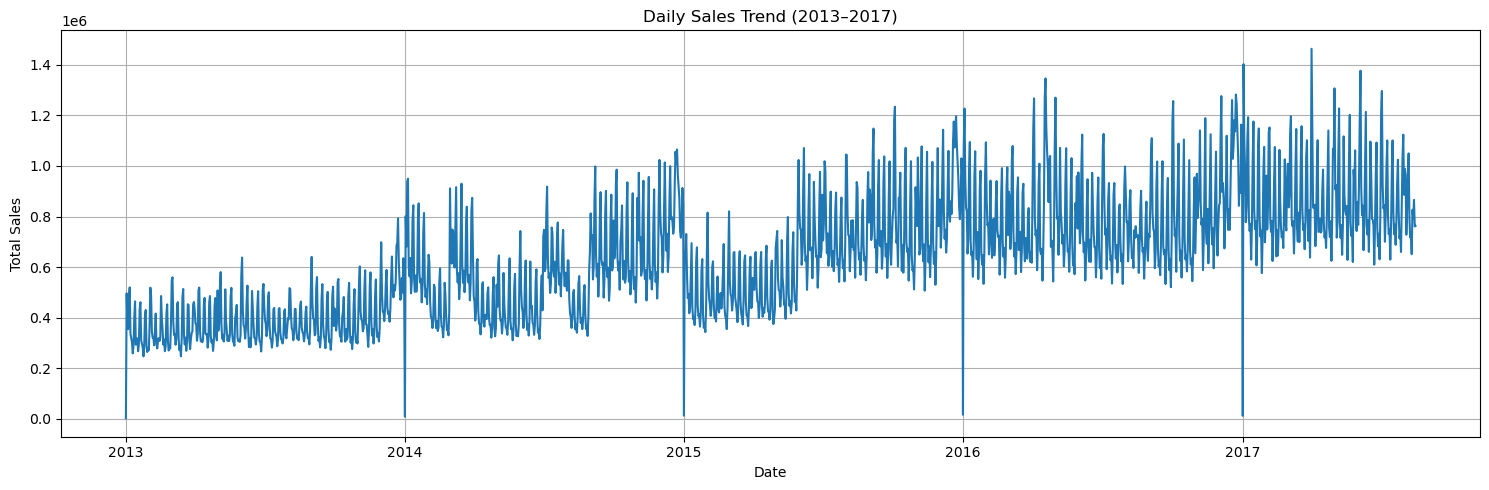

In [23]:

# Calculate total daily sales
daily_sales = train.groupby('date')['sales'].sum()

# Plot daily sales trend
plt.figure(figsize=(15, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title('Daily Sales Trend (2013–2017)')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)
plt.tight_layout()

plt.show()

# Monthly Sales Visualization

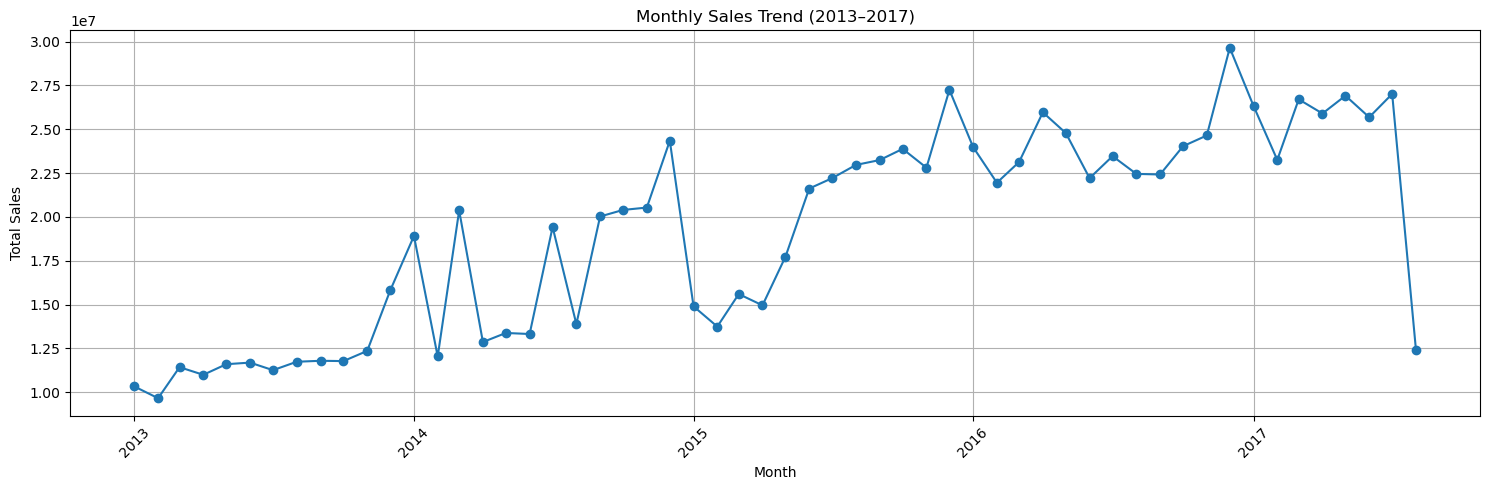

In [24]:

# Calculate monthly sales
monthly_sales = train.groupby(train['date'].dt.to_period('M'))['sales'].sum()

# Convert PeriodIndex to datetime
monthly_sales.index = monthly_sales.index.to_timestamp()

# Plot monthly sales
plt.figure(figsize=(15, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend (2013–2017)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()


# Product Family Sales Analysis

Top 10 Product Families by Sales:


family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

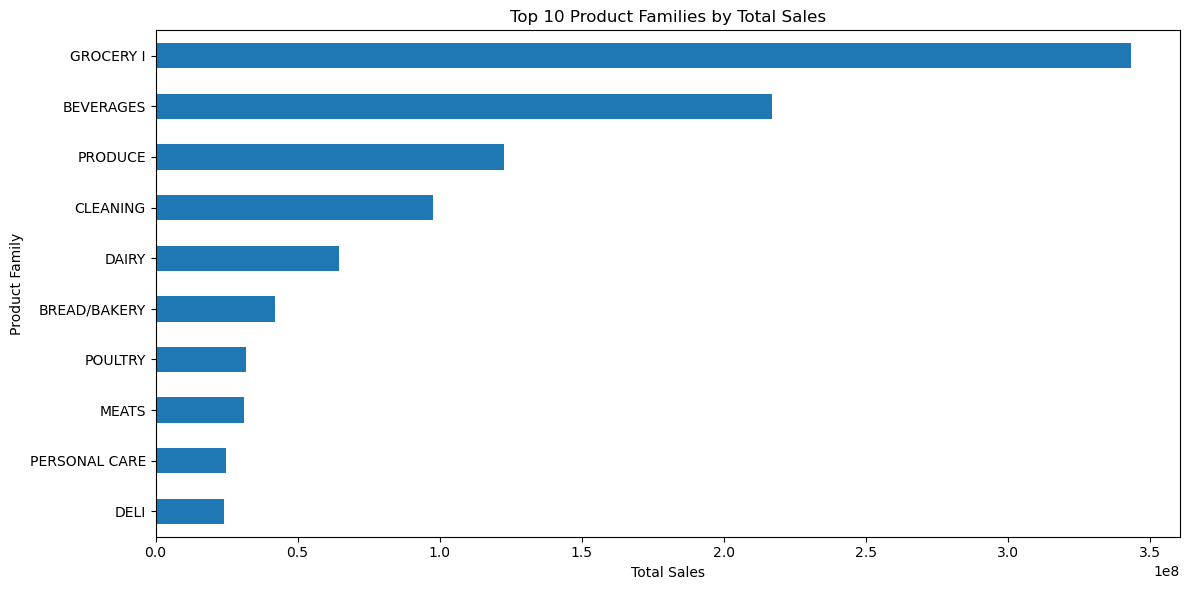

In [25]:

# Calculate sales by product family
family_sales = train.groupby('family')['sales'].sum().sort_values(ascending=False)

# Display top 10 product families
print("Top 10 Product Families by Sales:")
display(family_sales.head(10))

# Visualize top 10 families
plt.figure(figsize=(12, 6))
family_sales.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Product Families by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Family')
plt.tight_layout()

plt.show()


# Store-wise Sales Analysis

Top 10 Stores by Sales:


store_nbr
44    6.208755e+07
45    5.449801e+07
47    5.094831e+07
3     5.048191e+07
49    4.342010e+07
46    4.189606e+07
48    3.593313e+07
51    3.291149e+07
8     3.049429e+07
50    2.865302e+07
Name: sales, dtype: float64

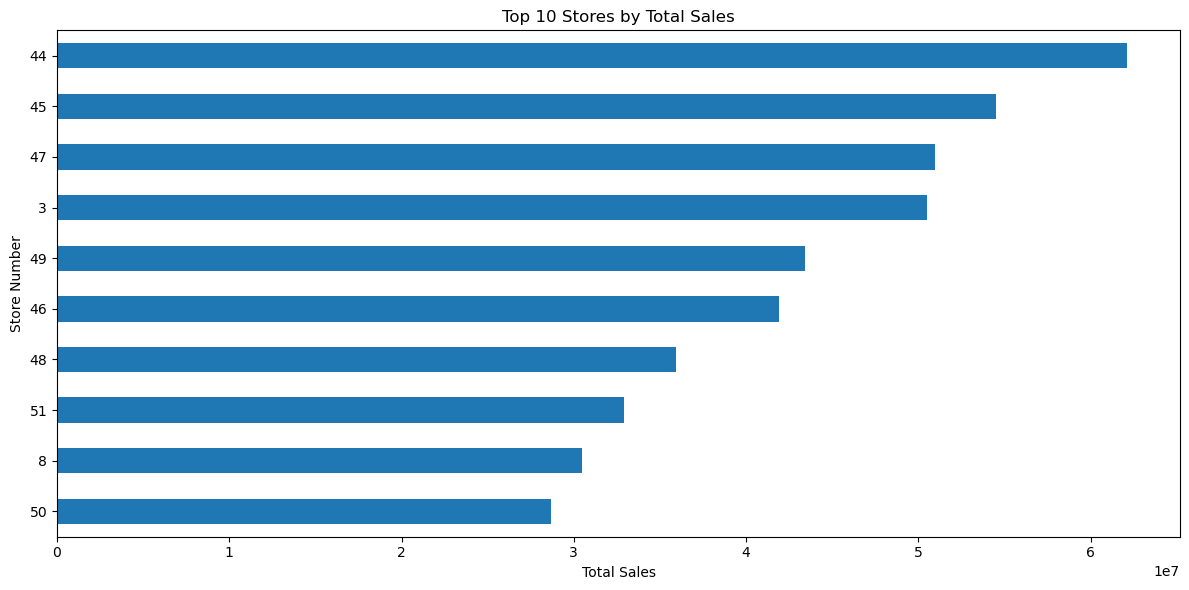

In [27]:

# Calculate sales by store
store_sales = train.groupby('store_nbr')['sales'].sum().sort_values(ascending=False)

# Display top 10 stores
print("Top 10 Stores by Sales:")
display(store_sales.head(10))

# Visualize top 10 stores
plt.figure(figsize=(12, 6))
store_sales.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Store Number')
plt.tight_layout()

plt.show()

# Sales Distribution Analysis

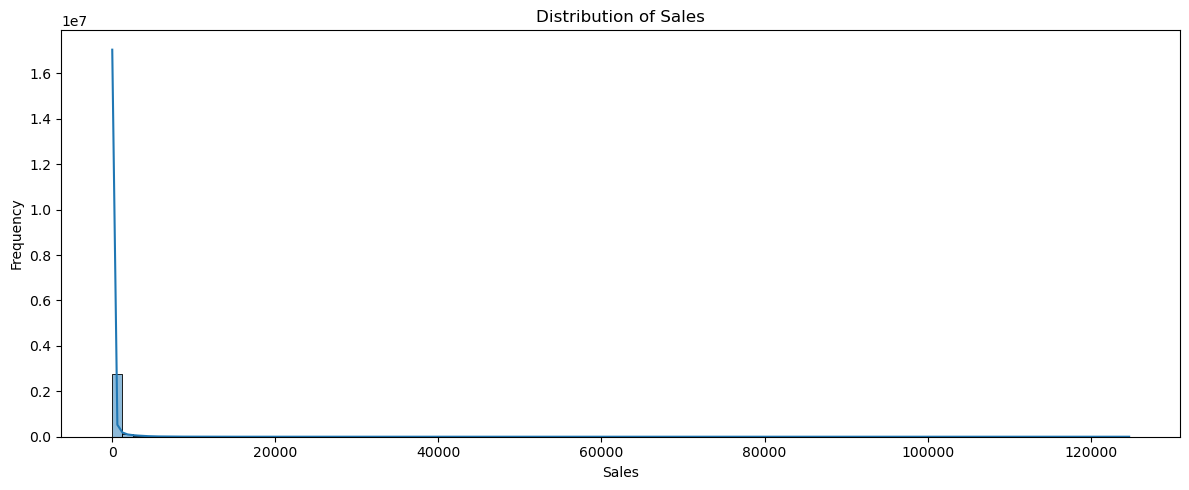

Sales Summary:
count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64


In [28]:

# Sales distribution
plt.figure(figsize=(12, 5))

sns.histplot(train['sales'], bins=100, kde=True)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.tight_layout()

plt.show()

# Sales summary
print("Sales Summary:")
print(train['sales'].describe())

# Time-Based Feature Engineering

In [29]:

# Extract date-based features
train['year'] = train['date'].dt.year
train['month'] = train['date'].dt.month
train['day'] = train['date'].dt.day
train['day_of_week'] = train['date'].dt.dayofweek
train['week_of_year'] = train['date'].dt.isocalendar().week.astype(int)
train['quarter'] = train['date'].dt.quarter

# Weekend indicator
train['is_weekend'] = (train['day_of_week'] >= 5).astype(int)

# Display updated dataset
display(train.head())

print("Updated Train Shape:", train.shape)
print("\nNew Columns:")
print(train.columns.tolist())


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,0
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,1,1,0
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,1,1,0
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,1,1,0
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,1,1,0


Updated Train Shape: (3000888, 13)

New Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend']


In [30]:
# Extract date-based features from test dataset

test['year'] = test['date'].dt.year
test['month'] = test['date'].dt.month
test['day'] = test['date'].dt.day
test['day_of_week'] = test['date'].dt.dayofweek
test['week_of_year'] = test['date'].dt.isocalendar().week.astype(int)
test['quarter'] = test['date'].dt.quarter

# Weekend indicator
test['is_weekend'] = (test['day_of_week'] >= 5).astype(int)

# Display updated test dataset
display(test.head())

print("Updated Test Shape:", test.shape)
print("\nTest Columns:")
print(test.columns.tolist())

,id,date,store_nbr,family,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend
0,3000888,2017-08-16,1,AUTOMOTIVE,0,2017,8,16,2,33,3,0
1,3000889,2017-08-16,1,BABY CARE,0,2017,8,16,2,33,3,0
2,3000890,2017-08-16,1,BEAUTY,2,2017,8,16,2,33,3,0
3,3000891,2017-08-16,1,BEVERAGES,20,2017,8,16,2,33,3,0
4,3000892,2017-08-16,1,BOOKS,0,2017,8,16,2,33,3,0


Updated Test Shape: (28512, 12)

Test Columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend']


In [31]:
# Compare train and test columns
train_features = set(train.columns) - {'sales'}
test_features = set(test.columns)

print("Columns in Train but not in Test:")
print(train_features - test_features)

print("\nColumns in Test but not in Train:")
print(test_features - train_features)

print("\nTrain and Test feature columns match:",
      train_features == test_features)

Columns in Train but not in Test:
set()

Columns in Test but not in Train:
set()

Train and Test feature columns match: True


# Load Supporting Datasets

In [32]:
# Load supporting datasets

stores = pd.read_csv(os.path.join(path, "stores.csv"))
oil = pd.read_csv(os.path.join(path, "oil.csv"))
holidays = pd.read_csv(os.path.join(path, "holidays_events.csv"))
transactions = pd.read_csv(os.path.join(path, "transactions.csv"))

In [33]:
# Check dataset shapes

print("Stores:", stores.shape)
print("Oil:", oil.shape)
print("Holidays:", holidays.shape)
print("Transactions:", transactions.shape)

Stores: (54, 5)
Oil: (1218, 2)
Holidays: (350, 6)
Transactions: (83488, 3)


In [34]:
# Check columns and missing values

datasets = {
    "Stores": stores,
    "Oil": oil,
    "Holidays": holidays,
    "Transactions": transactions
}

for name, df in datasets.items():
    print(f"\n--- {name} Dataset ---")
    print("Columns:", df.columns.tolist())
    print("\nMissing Values:")
    print(df.isnull().sum())


--- Stores Dataset ---
Columns: ['store_nbr', 'city', 'state', 'type', 'cluster']

Missing Values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

--- Oil Dataset ---
Columns: ['date', 'dcoilwtico']

Missing Values:
date           0
dcoilwtico    43
dtype: int64

--- Holidays Dataset ---
Columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

Missing Values:
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

--- Transactions Dataset ---
Columns: ['date', 'store_nbr', 'transactions']

Missing Values:
date            0
store_nbr       0
transactions    0
dtype: int64


In [35]:
# Convert supporting dataset dates to datetime

oil['date'] = pd.to_datetime(oil['date'])
holidays['date'] = pd.to_datetime(holidays['date'])
transactions['date'] = pd.to_datetime(transactions['date'])

# Sort datasets by date

oil = oil.sort_values('date')
holidays = holidays.sort_values('date')
transactions = transactions.sort_values('date')

# Verify date types

print("Oil Date Type:", oil['date'].dtype)
print("Holidays Date Type:", holidays['date'].dtype)
print("Transactions Date Type:", transactions['date'].dtype)

print("\nOil Missing Values:", oil['dcoilwtico'].isnull().sum())

Oil Date Type: datetime64[ns]
Holidays Date Type: datetime64[ns]
Transactions Date Type: datetime64[ns]

Oil Missing Values: 43


In [36]:
# Fill missing oil prices
oil['dcoilwtico'] = oil['dcoilwtico'].ffill().bfill()

# Verify missing values
print("Missing Oil Values After Filling:")
print(oil['dcoilwtico'].isnull().sum())

# Check updated dataset
display(oil.head(10))

Missing Oil Values After Filling:
0


,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20
5,2013-01-08,93.21
6,2013-01-09,93.08
7,2013-01-10,93.81
8,2013-01-11,93.60
9,2013-01-14,94.27


In [37]:
# Create a complete daily date range
all_dates = pd.date_range(
    start=train['date'].min(),
    end=test['date'].max(),
    freq='D'
)

# Reindex oil data to include every date
oil_daily = (
    oil.set_index('date')
       .reindex(all_dates)
       .rename_axis('date')
       .ffill()
       .bfill()
       .reset_index()
)

# Verify the updated oil dataset
print("Oil Daily Shape:", oil_daily.shape)
print("Missing Values:", oil_daily['dcoilwtico'].isnull().sum())
print("Duplicate Dates:", oil_daily['date'].duplicated().sum())

display(oil_daily.head(10))

Oil Daily Shape: (1704, 2)
Missing Values: 0
Duplicate Dates: 0


,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12
5,2013-01-06,93.12
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


In [38]:
# Merge daily oil prices with train and test datasets
train = train.merge(oil_daily, on='date', how='left')
test = test.merge(oil_daily, on='date', how='left')

# Check updated datasets
print("Updated Train Shape:", train.shape)
print("Updated Test Shape:", test.shape)

print("\nMissing Oil Values in Train:",
      train['dcoilwtico'].isnull().sum())

print("Missing Oil Values in Test:",
      test['dcoilwtico'].isnull().sum())

# Display updated train dataset
display(train.head())

Updated Train Shape: (3000888, 14)
Updated Test Shape: (28512, 13)

Missing Oil Values in Train: 0
Missing Oil Values in Test: 0


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,0,93.14
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,1,1,0,93.14
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,1,1,0,93.14
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,1,1,0,93.14
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,1,1,0,93.14


In [41]:
print("Train Columns:")
print(train.columns.tolist())

print("\nTest Columns:")
print(test.columns.tolist())

print("\nStores Columns:")
print(stores.columns.tolist())

Train Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend', 'dcoilwtico', 'city_x', 'state_x', 'type_x', 'cluster_x', 'city_y', 'state_y', 'type_y', 'cluster_y']

Test Columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend', 'dcoilwtico', 'city_x', 'state_x', 'type_x', 'cluster_x', 'city_y', 'state_y', 'type_y', 'cluster_y']

Stores Columns:
['store_nbr', 'city', 'state', 'type', 'cluster']


In [42]:
# Store feature columns
store_columns = ['city', 'state', 'type', 'cluster']

# Remove previously merged store columns
old_columns = (
    store_columns +
    [f'{col}_x' for col in store_columns] +
    [f'{col}_y' for col in store_columns]
)

train = train.drop(columns=old_columns, errors='ignore')
test = test.drop(columns=old_columns, errors='ignore')

# Merge stores dataset only once
train = train.merge(
    stores,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

test = test.merge(
    stores,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

# Verify results
print("Updated Train Shape:", train.shape)
print("Updated Test Shape:", test.shape)

print("\nMissing Store Values in Train:")
print(train[store_columns].isnull().sum())

print("\nMissing Store Values in Test:")
print(test[store_columns].isnull().sum())

display(train.head())

Updated Train Shape: (3000888, 18)
Updated Test Shape: (28512, 17)

Missing Store Values in Train:
city       0
state      0
type       0
cluster    0
dtype: int64

Missing Store Values in Test:
city       0
state      0
type       0
cluster    0
dtype: int64


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week_of_year,quarter,is_weekend,dcoilwtico,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,1,1,0,93.14,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,1,1,0,93.14,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,1,1,0,93.14,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,1,1,0,93.14,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,1,1,0,93.14,Quito,Pichincha,D,13


In [43]:
# Explore holidays dataset
print("First 10 Holiday Records:")
display(holidays.head(10))

print("\nHoliday Locale Counts:")
print(holidays['locale'].value_counts())

print("\nHoliday Type Counts:")
print(holidays['type'].value_counts())

print("\nTransferred Holiday Counts:")
print(holidays['transferred'].value_counts())

print("\nTotal Duplicate Dates:")
print(holidays['date'].duplicated().sum())

First 10 Holiday Records:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False



Holiday Locale Counts:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

Holiday Type Counts:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

Transferred Holiday Counts:
transferred
False    338
True      12
Name: count, dtype: int64

Total Duplicate Dates:
38


In [44]:
# Find all records with duplicate dates
duplicate_holidays = holidays[
    holidays.duplicated(subset='date', keep=False)
].sort_values(['date', 'locale', 'locale_name'])

# Display duplicate holiday records
display(
    duplicate_holidays[
        ['date', 'type', 'locale', 'locale_name',
         'description', 'transferred']
    ].head(20)
)

,date,type,locale,locale_name,description,transferred
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
11,2012-07-03,Holiday,Local,El Carmen,Cantonizacion de El Carmen,False
10,2012-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo,False
32,2012-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas,False
33,2012-12-22,Additional,National,Ecuador,Navidad-3,False
35,2012-12-24,Bridge,National,Ecuador,Puente Navidad,False
36,2012-12-24,Additional,National,Ecuador,Navidad-1,False
39,2012-12-31,Bridge,National,Ecuador,Puente Primer dia del ano,False


In [45]:
# Check transferred holidays
transferred_holidays = holidays[
    holidays['transferred'] == True
]

print("Total Transferred Holidays:",
      len(transferred_holidays))

display(transferred_holidays[
    ['date', 'type', 'locale', 'locale_name',
     'description', 'transferred']
])

# Check Work Day records
print("\nWork Day Records:")
display(holidays[holidays['type'] == 'Work Day'])

Total Transferred Holidays: 12


,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True



Work Day Records:


,date,type,locale,locale_name,description,transferred
42,2013-01-05,Work Day,National,Ecuador,Recupero puente Navidad,False
43,2013-01-12,Work Day,National,Ecuador,Recupero puente primer dia del ano,False
149,2014-12-20,Work Day,National,Ecuador,Recupero Puente Navidad,False
161,2015-01-10,Work Day,National,Ecuador,Recupero Puente Primer dia del ano,False
283,2016-11-12,Work Day,National,Ecuador,Recupero Puente Dia de Difuntos,False


In [46]:
# Keep valid holidays within the train and test date range
holiday_base = holidays[
    (holidays['transferred'] == False) &
    (holidays['date'] >= train['date'].min()) &
    (holidays['date'] <= test['date'].max())
].copy()

# National holidays apply to all stores
national = holiday_base[
    holiday_base['locale'] == 'National'
].merge(
    stores[['store_nbr']],
    how='cross'
)

# Regional holidays apply to matching states
regional = holiday_base[
    holiday_base['locale'] == 'Regional'
].merge(
    stores[['store_nbr', 'state']],
    left_on='locale_name',
    right_on='state',
    how='inner'
)

# Local holidays apply to matching cities
local = holiday_base[
    holiday_base['locale'] == 'Local'
].merge(
    stores[['store_nbr', 'city']],
    left_on='locale_name',
    right_on='city',
    how='inner'
)

# Combine all matching holiday records
store_holidays = pd.concat(
    [national, regional, local],
    ignore_index=True
)

# Define holiday features
holiday_types = ['Holiday', 'Transfer', 'Additional', 'Bridge']

store_holidays['is_holiday'] = (
    store_holidays['type'].isin(holiday_types)
).astype(int)

store_holidays['is_event'] = (
    store_holidays['type'] == 'Event'
).astype(int)

store_holidays['is_work_day'] = (
    store_holidays['type'] == 'Work Day'
).astype(int)

store_holidays['is_national_holiday'] = (
    (store_holidays['locale'] == 'National') &
    (store_holidays['type'].isin(holiday_types))
).astype(int)

store_holidays['is_regional_holiday'] = (
    (store_holidays['locale'] == 'Regional') &
    (store_holidays['type'].isin(holiday_types))
).astype(int)

store_holidays['is_local_holiday'] = (
    (store_holidays['locale'] == 'Local') &
    (store_holidays['type'].isin(holiday_types))
).astype(int)

store_holidays['is_bridge_day'] = (
    store_holidays['type'] == 'Bridge'
).astype(int)

store_holidays['is_additional_holiday'] = (
    store_holidays['type'] == 'Additional'
).astype(int)

store_holidays['is_transfer_day'] = (
    store_holidays['type'] == 'Transfer'
).astype(int)

# Create one record per store and date
holiday_feature_cols = [
    'is_holiday',
    'is_event',
    'is_work_day',
    'is_national_holiday',
    'is_regional_holiday',
    'is_local_holiday',
    'is_bridge_day',
    'is_additional_holiday',
    'is_transfer_day'
]

holiday_features = (
    store_holidays
    .groupby(['date', 'store_nbr'])[holiday_feature_cols]
    .max()
    .reset_index()
)

# Verify the result
print("Store Holiday Features Shape:", holiday_features.shape)

print("Duplicate Store-Date Records:",
      holiday_features.duplicated(['date', 'store_nbr']).sum())

display(holiday_features.head(10))

Store Holiday Features Shape: (7938, 11)
Duplicate Store-Date Records: 0


,date,store_nbr,is_holiday,is_event,is_work_day,is_national_holiday,is_regional_holiday,is_local_holiday,is_bridge_day,is_additional_holiday,is_transfer_day
0,2013-01-01,1,1,0,0,1,0,0,0,0,0
1,2013-01-01,2,1,0,0,1,0,0,0,0,0
2,2013-01-01,3,1,0,0,1,0,0,0,0,0
3,2013-01-01,4,1,0,0,1,0,0,0,0,0
4,2013-01-01,5,1,0,0,1,0,0,0,0,0
5,2013-01-01,6,1,0,0,1,0,0,0,0,0
6,2013-01-01,7,1,0,0,1,0,0,0,0,0
7,2013-01-01,8,1,0,0,1,0,0,0,0,0
8,2013-01-01,9,1,0,0,1,0,0,0,0,0
9,2013-01-01,10,1,0,0,1,0,0,0,0,0


In [47]:
 # Merge holiday features with train and test
train = train.merge(
    holiday_features,
    on=['date', 'store_nbr'],
    how='left',
    validate='many_to_one'
)

test = test.merge(
    holiday_features,
    on=['date', 'store_nbr'],
    how='left',
    validate='many_to_one'
)

# Fill missing holiday features with 0
train[holiday_feature_cols] = (
    train[holiday_feature_cols].fillna(0).astype('int8')
)

test[holiday_feature_cols] = (
    test[holiday_feature_cols].fillna(0).astype('int8')
)

# Verify updated datasets
print("Updated Train Shape:", train.shape)
print("Updated Test Shape:", test.shape)

print("\nMissing Holiday Values in Train:")
print(train[holiday_feature_cols].isnull().sum().sum())

print("\nMissing Holiday Values in Test:")
print(test[holiday_feature_cols].isnull().sum().sum())

display(train.head())

Updated Train Shape: (3000888, 27)
Updated Test Shape: (28512, 26)

Missing Holiday Values in Train:
0

Missing Holiday Values in Test:
0


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,...,cluster,is_holiday,is_event,is_work_day,is_national_holiday,is_regional_holiday,is_local_holiday,is_bridge_day,is_additional_holiday,is_transfer_day
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,...,13,1,0,0,1,0,0,0,0,0
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,...,13,1,0,0,1,0,0,0,0,0
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,...,13,1,0,0,1,0,0,0,0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,...,13,1,0,0,1,0,0,0,0,0
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,...,13,1,0,0,1,0,0,0,0,0


In [50]:
# Explore transactions dataset
print("Transactions Shape:", transactions.shape)

print("\nColumns:")
print(transactions.columns.tolist())

print("\nDate Range:")
print("Start Date:", transactions['date'].min())
print("End Date:", transactions['date'].max())

print("\nMissing Values:")
print(transactions.isnull().sum())

print("\nDuplicate Date-Store Records:",
      transactions.duplicated(
          subset=['date', 'store_nbr']
      ).sum())

print("\nFirst 5 Records:")
display(transactions.head())

print("\nLast 5 Records:")
display(transactions.tail())

Transactions Shape: (83488, 3)

Columns:
['date', 'store_nbr', 'transactions']

Date Range:
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00

Missing Values:
date            0
store_nbr       0
transactions    0
dtype: int64

Duplicate Date-Store Records: 0

First 5 Records:


,date,store_nbr,transactions
0,2013-01-01,25,770
26,2013-01-02,30,708
27,2013-01-02,31,1401
28,2013-01-02,32,776
29,2013-01-02,33,1163



Last 5 Records:


,date,store_nbr,transactions
83455,2017-08-15,22,766
83456,2017-08-15,23,946
83457,2017-08-15,24,2138
83446,2017-08-15,13,842
83487,2017-08-15,54,802


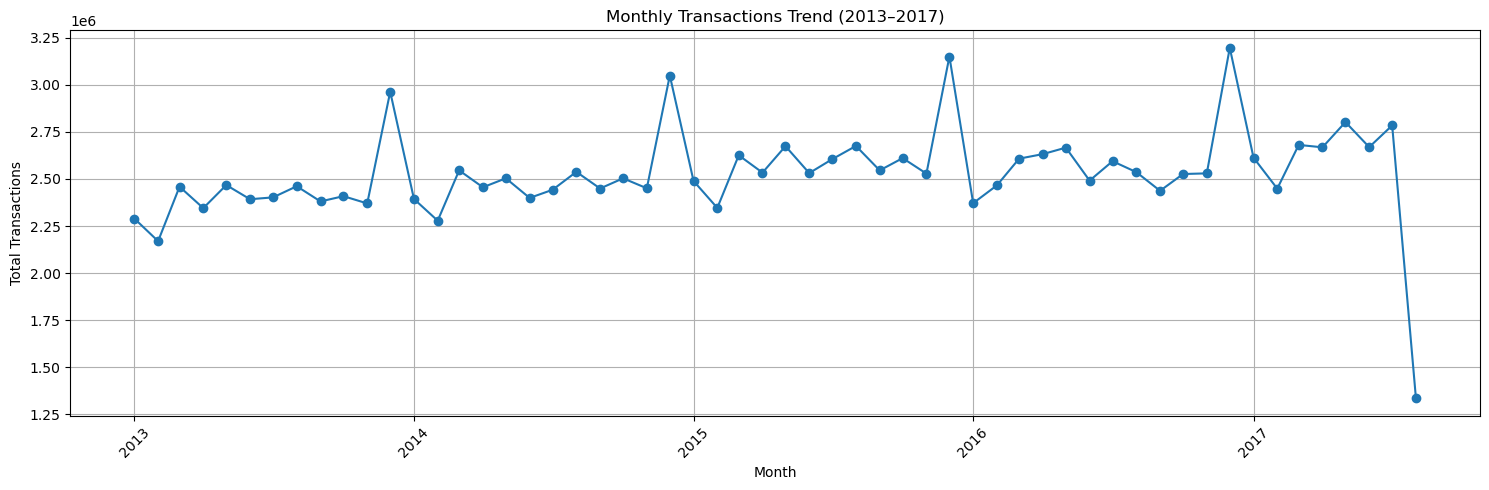

In [53]:
# Calculate monthly transactions
monthly_transactions = (
    transactions.groupby(
        transactions['date'].dt.to_period('M')
    )['transactions'].sum()
)

# Convert month index to datetime
monthly_transactions.index = (
    monthly_transactions.index.to_timestamp()
)

# Plot monthly transaction trend
plt.figure(figsize=(15, 5))

plt.plot(
    monthly_transactions.index,
    monthly_transactions.values,
    marker='o'
)

plt.title('Monthly Transactions Trend (2013–2017)')
plt.xlabel('Month')
plt.ylabel('Total Transactions')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [55]:
import importlib.util

packages = ['sklearn', 'lightgbm', 'xgboost', 'catboost']

for package in packages:
    status = "Installed" if importlib.util.find_spec(package) else "Not Installed"
    print(f"{package}: {status}")

sklearn: Installed
lightgbm: Not Installed
xgboost: Not Installed
catboost: Not Installed


In [56]:
# Select model features
feature_cols = [
    'store_nbr', 'family', 'onpromotion',
    'year', 'month', 'day', 'day_of_week',
    'week_of_year', 'quarter', 'is_weekend',
    'dcoilwtico', 'city', 'state', 'type', 'cluster',
    'is_holiday', 'is_event', 'is_work_day',
    'is_national_holiday', 'is_regional_holiday',
    'is_local_holiday', 'is_bridge_day',
    'is_additional_holiday', 'is_transfer_day'
]

# Create feature datasets
X = train[feature_cols].copy()
X_test = test[feature_cols].copy()

# Encode categorical columns consistently
categorical_cols = ['family', 'city', 'state', 'type']
category_mappings = {}

for col in categorical_cols:
    cat = train[col].astype('category')
    category_mappings[col] = cat.cat.categories

    X[col] = cat.cat.codes.astype('int8')

    X_test[col] = pd.Categorical(
        test[col],
        categories=category_mappings[col]
    ).codes.astype('int8')

# Check for unknown categories in test
print("Unknown Test Categories:")
for col in categorical_cols:
    print(col, (X_test[col] == -1).sum())

# Create time-based validation split
validation_start = pd.Timestamp('2017-07-31')

train_mask = train['date'] < validation_start
valid_mask = train['date'] >= validation_start

print("\nFeature Dataset Shapes:")
print("X:", X.shape)
print("X_test:", X_test.shape)

print("\nTraining Period:")
print(train.loc[train_mask, 'date'].min(),
      "to",
      train.loc[train_mask, 'date'].max())

print("\nValidation Period:")
print(train.loc[valid_mask, 'date'].min(),
      "to",
      train.loc[valid_mask, 'date'].max())

print("\nTraining Rows:", train_mask.sum())
print("Validation Rows:", valid_mask.sum())

Unknown Test Categories:
family 0
city 0
state 0
type 0

Feature Dataset Shapes:
X: (3000888, 24)
X_test: (28512, 24)

Training Period:
2013-01-01 00:00:00 to 2017-07-30 00:00:00

Validation Period:
2017-07-31 00:00:00 to 2017-08-15 00:00:00

Training Rows: 2972376
Validation Rows: 28512


In [57]:
# Reduce feature memory usage
X = X.astype(np.float32)
X_test = X_test.astype(np.float32)

# Prepare target variable
y_train = np.log1p(
    train.loc[train_mask, 'sales'].to_numpy(dtype=np.float32)
)

# Keep actual validation sales for evaluation
y_valid = train.loc[
    valid_mask, 'sales'
].to_numpy(dtype=np.float32)

# Check prepared data
print("X Training Shape:", X.loc[train_mask].shape)
print("X Validation Shape:", X.loc[valid_mask].shape)
print("X Test Shape:", X_test.shape)

print("\nTarget Training Shape:", y_train.shape)
print("Target Validation Shape:", y_valid.shape)

print("\nNegative Sales Values:", (train['sales'] < 0).sum())
print("Target Missing Values:", np.isnan(y_train).sum())

X Training Shape: (2972376, 24)
X Validation Shape: (28512, 24)
X Test Shape: (28512, 24)

Target Training Shape: (2972376,)
Target Validation Shape: (28512,)

Negative Sales Values: 0
Target Missing Values: 0


In [58]:
# Check Date Ordering

print("Train dates sorted:",
      train['date'].is_monotonic_increasing)

print("First Date:", train['date'].min())
print("Last Date:", train['date'].max())

print("\nUnique Store-Family Combinations:",
      train.groupby(['store_nbr', 'family']).ngroups)

Train dates sorted: True
First Date: 2013-01-01 00:00:00
Last Date: 2017-08-15 00:00:00

Unique Store-Family Combinations: 1782


In [59]:
# Check Missing Dates Before Creating Lag Features

# Check unique dates
unique_dates = pd.DatetimeIndex(
    train['date'].drop_duplicates().sort_values()
)

# Find missing calendar dates
all_dates = pd.date_range(
    start=train['date'].min(),
    end=train['date'].max(),
    freq='D'
)

missing_dates = all_dates.difference(unique_dates)

print("Total Unique Dates:", len(unique_dates))
print("Missing Calendar Dates:", len(missing_dates))

print("\nMissing Dates:")
print(missing_dates.tolist())

# Check observations per store-family combination
group_counts = train.groupby(
    ['store_nbr', 'family']
).size()

print("\nMinimum Records per Combination:", group_counts.min())
print("Maximum Records per Combination:", group_counts.max())

Total Unique Dates: 1684
Missing Calendar Dates: 4

Missing Dates:
[Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]

Minimum Records per Combination: 1684
Maximum Records per Combination: 1684


In [60]:
# Create Historical Lag Features

# Prepare historical sales data
lag_source = train[
    ['store_nbr', 'family', 'date', 'sales']
].copy()

# Preserve original row numbers
lag_source['_row_id'] = train.index.to_numpy()

# Identify missing calendar dates
all_dates = pd.date_range(
    train['date'].min(),
    train['date'].max(),
    freq='D'
)

missing_dates = all_dates.difference(
    pd.DatetimeIndex(train['date'].unique())
)

# Create temporary records for missing Christmas dates
missing_rows = pd.MultiIndex.from_product(
    [
        np.sort(train['store_nbr'].unique()),
        np.sort(train['family'].unique()),
        missing_dates
    ],
    names=['store_nbr', 'family', 'date']
).to_frame(index=False)

# These temporary records represent zero sales
missing_rows['sales'] = 0.0
missing_rows['_row_id'] = -1

# Combine actual and temporary historical records
lag_source = pd.concat(
    [lag_source, missing_rows],
    ignore_index=True
)

# Sort each store-family series chronologically
lag_source = lag_source.sort_values(
    ['store_nbr', 'family', 'date']
)

# Create exact calendar-based lag features
for lag in [7, 14, 28]:
    lag_source[f'lag_{lag}'] = (
        lag_source.groupby(
            ['store_nbr', 'family']
        )['sales'].shift(lag)
    )

# Keep lag values for original training rows only
lag_values = lag_source[
    lag_source['_row_id'] >= 0
].set_index('_row_id')

# Add lag features to original train dataset
for lag in [7, 14, 28]:
    train[f'lag_{lag}'] = (
        lag_values[f'lag_{lag}']
        .reindex(train.index)
        .fillna(0)
        .astype('float32')
    )

# Verify results
print("Temporary Christmas Records:", len(missing_rows))
print("Updated Train Shape:", train.shape)

print("\nMissing Lag Values:")
print(train[['lag_7', 'lag_14', 'lag_28']].isnull().sum())

display(
    train[
        ['date', 'store_nbr', 'family',
         'sales', 'lag_7', 'lag_14', 'lag_28']
    ].head(10)
)

Temporary Christmas Records: 7128
Updated Train Shape: (3000888, 30)

Missing Lag Values:
lag_7     0
lag_14    0
lag_28    0
dtype: int64


,date,store_nbr,family,sales,lag_7,lag_14,lag_28
0,2013-01-01,1,AUTOMOTIVE,0.0,0.0,0.0,0.0
1,2013-01-01,1,BABY CARE,0.0,0.0,0.0,0.0
2,2013-01-01,1,BEAUTY,0.0,0.0,0.0,0.0
3,2013-01-01,1,BEVERAGES,0.0,0.0,0.0,0.0
4,2013-01-01,1,BOOKS,0.0,0.0,0.0,0.0
5,2013-01-01,1,BREAD/BAKERY,0.0,0.0,0.0,0.0
6,2013-01-01,1,CELEBRATION,0.0,0.0,0.0,0.0
7,2013-01-01,1,CLEANING,0.0,0.0,0.0,0.0
8,2013-01-01,1,DAIRY,0.0,0.0,0.0,0.0
9,2013-01-01,1,DELI,0.0,0.0,0.0,0.0


In [61]:
# Add lag features to the existing feature matrix
lag_cols = ['lag_7', 'lag_14', 'lag_28']

X[lag_cols] = train[lag_cols].to_numpy(
    dtype=np.float32
)

# Total model features
model_feature_cols = feature_cols + lag_cols

# Create training array
n_train = int(train_mask.sum())

X_array = X.to_numpy(dtype=np.float32, copy=False)
X_train = X_array[:n_train]

# Verify prepared features
print("Total Model Features:", len(model_feature_cols))
print("Training Feature Shape:", X_train.shape)
print("Expected Training Rows:", len(y_train))

print("\nLag Feature Summary:")
print(train[lag_cols].describe())

print("\nTraining Feature Missing Values:",
      np.isnan(X_train).sum())

Total Model Features: 27
Training Feature Shape: (2972376, 27)
Expected Training Rows: 2972376

Lag Feature Summary:
              lag_7        lag_14        lag_28
count  3.000888e+06  3.000888e+06  3.000888e+06
mean   3.548409e+02  3.530185e+02  3.491278e+02
std    1.088704e+03  1.086907e+03  1.081562e+03
min    0.000000e+00  0.000000e+00  0.000000e+00
25%    0.000000e+00  0.000000e+00  0.000000e+00
50%    1.000000e+01  1.000000e+01  9.000000e+00
75%    1.929943e+02  1.910000e+02  1.870000e+02
max    1.247170e+05  1.247170e+05  1.247170e+05

Training Feature Missing Values: 0


In [63]:
# Train the First Regression Model

from sklearn.ensemble import HistGradientBoostingRegressor
import time

# Initialize regression model
model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

# Train the model
start_time = time.time()

model.fit(X_train, y_train)

end_time = time.time()

# Display training results
print("Model Training Completed Successfully!")
print("Iterations:", model.n_iter_)
print("Training Time:",round((end_time - start_time) / 60, 2), "minutes")

Model Training Completed Successfully!
Iterations: 100
Training Time: 0.74 minutes


In [64]:
# Generate Validation Predictions

# Generate recursive validation predictions
validation_dates = sorted(
    train.loc[valid_mask, 'date'].unique()
)

# Store predictions for previous validation dates
pred_lookup = {}

# Store final validation predictions
valid_predictions = pd.Series(
    index=train.index[valid_mask],
    dtype='float32'
)

for current_date in validation_dates:

    current_date = pd.Timestamp(current_date)

    # Select rows for the current date
    day_mask = (
        valid_mask &
        (train['date'] == current_date)
    )

    day_indices = train.index[day_mask]

    # Prepare model features
    day_X = X.loc[
        day_indices, model_feature_cols
    ].copy()

    day_meta = train.loc[
        day_indices, ['store_nbr', 'family']
    ]

    # Replace validation-period lag values with predictions
    for lag in [7, 14, 28]:

        source_date = current_date - pd.Timedelta(days=lag)

        if source_date >= validation_start:

            day_X[f'lag_{lag}'] = [
                pred_lookup[(store, family, source_date)]
                for store, family in zip(
                    day_meta['store_nbr'],
                    day_meta['family']
                )
            ]

    # Predict on log scale
    predicted_log = model.predict(
        day_X.to_numpy(dtype=np.float32)
    )

    # Convert predictions to original sales scale
    predicted_sales = np.maximum(
        np.expm1(predicted_log),
        0
    )

    # Save predictions
    valid_predictions.loc[day_indices] = predicted_sales

    # Store predictions for future lag calculations
    for store, family, prediction in zip(
        day_meta['store_nbr'],
        day_meta['family'],
        predicted_sales
    ):
        pred_lookup[
            (store, family, current_date)
        ] = float(prediction)

# Verify predictions
print("Total Validation Dates:", len(validation_dates))
print("Total Validation Predictions:", valid_predictions.notna().sum())
print("Missing Predictions:", valid_predictions.isnull().sum())

print("\nValidation Prediction Summary:")
print(valid_predictions.describe())

display(
    pd.DataFrame({
        'date': train.loc[valid_predictions.index, 'date'],
        'actual_sales': y_valid,
        'predicted_sales': valid_predictions.to_numpy()
    }).head(10)
)

Total Validation Dates: 16
Total Validation Predictions: 28512
Missing Predictions: 0

Validation Prediction Summary:
count    28512.000000
mean       479.515959
std       1257.031621
min          0.000000
25%          3.765171
50%         28.038737
75%        284.571200
max      11317.710946
dtype: float64


,date,actual_sales,predicted_sales
2972376,2017-07-31,8.000000,2.027892
2972377,2017-07-31,0.000000,0.047366
2972378,2017-07-31,3.000000,2.916615
2972379,2017-07-31,2414.000000,2263.116342
2972380,2017-07-31,1.000000,0.486114
2972381,2017-07-31,370.993988,380.758306
2972382,2017-07-31,3.000000,12.261152
2972383,2017-07-31,678.000000,646.443715
2972384,2017-07-31,727.000000,795.085273
2972385,2017-07-31,189.110001,172.159428


In [65]:
# Evaluate Model Performance

from sklearn.metrics import (
    mean_squared_log_error,
    mean_squared_error,
    mean_absolute_error
)

# Actual and predicted validation sales
actual_valid = train.loc[
    valid_mask, 'sales'
].to_numpy(dtype=np.float64)

predicted_valid = valid_predictions.to_numpy(
    dtype=np.float64
)

# Calculate evaluation metrics
rmsle = np.sqrt(
    mean_squared_log_error(
        actual_valid,
        predicted_valid
    )
)

rmse = np.sqrt(
    mean_squared_error(
        actual_valid,
        predicted_valid
    )
)

mae = mean_absolute_error(
    actual_valid,
    predicted_valid
)

# Display results
print("MODEL PERFORMANCE EVALUATION")
print("-----------------------------")
print("RMSLE:", round(rmsle, 4))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))


MODEL PERFORMANCE EVALUATION
-----------------------------
RMSLE: 0.4617
RMSE: 269.48
MAE: 79.56


In [66]:
#  Compare with Seasonal Naive Forecast

# Generate 7-day seasonal naive predictions
baseline_predictions = pd.Series(
    index=train.index[valid_mask],
    dtype='float64'
)

baseline_by_date = {}

for current_date in validation_dates:

    current_date = pd.Timestamp(current_date)

    day_mask = (
        valid_mask &
        (train['date'] == current_date)
    )

    day_indices = train.index[day_mask]

    day_keys = pd.MultiIndex.from_frame(
        train.loc[day_indices, ['store_nbr', 'family']]
    )

    source_date = current_date - pd.Timedelta(days=7)

    # Use historical actual sales before validation
    if source_date < validation_start:

        source_day = train.loc[
            train['date'] == source_date,
            ['store_nbr', 'family', 'sales']
        ]

        source_sales = source_day.set_index(
            ['store_nbr', 'family']
        )['sales']

    # Use previous baseline predictions during validation
    else:
        source_sales = baseline_by_date[source_date]

    day_predictions = (
        source_sales.reindex(day_keys)
        .fillna(0)
        .to_numpy(dtype=np.float64)
    )

    baseline_predictions.loc[day_indices] = day_predictions

    baseline_by_date[current_date] = pd.Series(
        day_predictions,
        index=day_keys
    )

# Calculate baseline metrics
baseline_valid = baseline_predictions.to_numpy()

baseline_rmsle = np.sqrt(
    mean_squared_log_error(actual_valid, baseline_valid)
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_valid, baseline_valid)
)

baseline_mae = mean_absolute_error(
    actual_valid, baseline_valid
)

# Compare both models
comparison = pd.DataFrame({
    'RMSLE': [rmsle, baseline_rmsle],
    'RMSE': [rmse, baseline_rmse],
    'MAE': [mae, baseline_mae]
}, index=[
    'HistGradientBoosting',
    '7-Day Seasonal Naive'
])

display(comparison.round(4))

print(
    "\nRMSLE Improvement (%):",
    round(
        ((baseline_rmsle - rmsle) / baseline_rmsle) * 100,
        2
    )
)

,RMSLE,RMSE,MAE
HistGradientBoosting,0.4617,269.4757,79.5570
7-Day Seasonal Naive,0.6170,348.3817,96.5354



RMSLE Improvement (%): 25.18


In [67]:
# Train Final Model on Complete Dataset

# Prepare complete training data
X_full = X[model_feature_cols].to_numpy(
    dtype=np.float32,
    copy=False
)

y_full = np.log1p(
    train['sales'].to_numpy(dtype=np.float32)
)

# Initialize final regression model
final_model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

# Train on complete dataset
start_time = time.time()

final_model.fit(X_full, y_full)

end_time = time.time()

# Display results
print("Final Model Training Completed!")

print("Training Rows:", X_full.shape[0])
print("Total Features:", X_full.shape[1])
print("Iterations:", final_model.n_iter_)

print(
    "Training Time:",
    round((end_time - start_time) / 60, 2),
    "minutes"
)

Final Model Training Completed!
Training Rows: 3000888
Total Features: 27
Iterations: 100
Training Time: 0.74 minutes


In [68]:
# Forecast Sales for Test Dataset

# Prepare test features
X_test_final = X_test[feature_cols].copy()

# Test dates
test_dates = sorted(pd.to_datetime(test['date'].unique()))

train_last_date = train['date'].max()

# Identify historical dates needed for lag features
needed_dates = {
    current_date - pd.Timedelta(days=lag)
    for current_date in test_dates
    for lag in [7, 14, 28]
    if current_date - pd.Timedelta(days=lag) <= train_last_date
}

# Extract only required historical sales
historical_rows = train.loc[
    train['date'].isin(needed_dates),
    ['date', 'store_nbr', 'family', 'sales']
]

# Create historical sales lookup
historical_lookup = {
    pd.Timestamp(date): group.set_index(
        ['store_nbr', 'family']
    )['sales']
    for date, group in historical_rows.groupby('date')
}

# Store predictions for recursive forecasting
prediction_lookup = {}

# Store final test predictions
test_predictions = pd.Series(
    index=test.index,
    dtype='float32'
)

# Generate predictions date by date
for current_date in test_dates:

    current_date = pd.Timestamp(current_date)

    day_mask = test['date'] == current_date
    day_indices = test.index[day_mask]

    day_meta = test.loc[
        day_indices, ['store_nbr', 'family']
    ]

    day_keys = pd.MultiIndex.from_frame(day_meta)

    day_X = X_test_final.loc[day_indices].copy()

    # Calculate lag features
    for lag in [7, 14, 28]:

        source_date = current_date - pd.Timedelta(days=lag)

        if source_date <= train_last_date:
            source_sales = historical_lookup.get(source_date)
        else:
            source_sales = prediction_lookup.get(source_date)

        if source_sales is None:
            raise ValueError(
                f"Historical sales unavailable for {source_date}"
            )

        day_X[f'lag_{lag}'] = (
            source_sales.reindex(day_keys)
            .fillna(0)
            .to_numpy(dtype=np.float32)
        )

    # Predict sales on log scale
    predicted_log = final_model.predict(
        day_X[model_feature_cols].to_numpy(
            dtype=np.float32
        )
    )

    # Convert predictions to original sales scale
    predicted_sales = np.maximum(
        np.expm1(predicted_log),
        0
    )

    # Save predictions
    test_predictions.loc[day_indices] = predicted_sales

    # Save predictions for future lag calculations
    prediction_lookup[current_date] = pd.Series(
        predicted_sales,
        index=day_keys
    )

# Verify final predictions
print("Forecast Start Date:", test['date'].min())
print("Forecast End Date:", test['date'].max())

print("\nTotal Test Predictions:", test_predictions.notna().sum())
print("Missing Predictions:", test_predictions.isnull().sum())
print("Negative Predictions:", (test_predictions < 0).sum())

print("\nPrediction Summary:")
print(test_predictions.describe())

# Display sample predictions
display(pd.DataFrame({
    'id': test['id'],
    'date': test['date'],
    'store_nbr': test['store_nbr'],
    'family': test['family'],
    'predicted_sales': test_predictions
}).head(10))

Forecast Start Date: 2017-08-16 00:00:00
Forecast End Date: 2017-08-31 00:00:00

Total Test Predictions: 28512
Missing Predictions: 0
Negative Predictions: 0

Prediction Summary:
count    28512.000000
mean       423.180747
std       1120.186720
min          0.000000
25%          3.927319
50%         28.249264
75%        250.331730
max      10069.538572
dtype: float64


,id,date,store_nbr,family,predicted_sales
0,3000888,2017-08-16,1,AUTOMOTIVE,4.894975
1,3000889,2017-08-16,1,BABY CARE,0.038951
2,3000890,2017-08-16,1,BEAUTY,3.592998
3,3000891,2017-08-16,1,BEVERAGES,2310.674593
4,3000892,2017-08-16,1,BOOKS,0.039041
5,3000893,2017-08-16,1,BREAD/BAKERY,394.713554
6,3000894,2017-08-16,1,CELEBRATION,9.230458
7,3000895,2017-08-16,1,CLEANING,741.411665
8,3000896,2017-08-16,1,DAIRY,835.114060
9,3000897,2017-08-16,1,DELI,143.887180


In [70]:
# Create Final Kaggle Submission 

# Create final submission dataframe
submission = pd.DataFrame({
    'id': test['id'].to_numpy(),
    'sales': test_predictions.to_numpy(dtype=np.float64)
})

# Sort by ID
submission = submission.sort_values('id').reset_index(drop=True)

# Validate submission
print("Submission Shape:", submission.shape)
print("\nColumns:", submission.columns.tolist())

print("\nMissing Values:")
print(submission.isnull().sum())

print("\nDuplicate IDs:", submission['id'].duplicated().sum())
print("Negative Sales:", (submission['sales'] < 0).sum())

# Save CSV file
submission.to_csv('submission.csv', index=False)

print("\nSubmission file saved successfully!")
print("File Location:", os.path.abspath('submission.csv'))

# Preview submission
display(submission.head(10))


Submission Shape: (28512, 2)

Columns: ['id', 'sales']

Missing Values:
id       0
sales    0
dtype: int64

Duplicate IDs: 0
Negative Sales: 0

Submission file saved successfully!
File Location: C:\Users\Simran\FutureInterns_ML\submission.csv


,id,sales
0,3000888,4.894975
1,3000889,0.038951
2,3000890,3.592998
3,3000891,2310.674593
4,3000892,0.039041
5,3000893,394.713554
6,3000894,9.230458
7,3000895,741.411665
8,3000896,835.114060
9,3000897,143.887180


In [71]:
# Read the saved submission file
final_check = pd.read_csv('submission.csv')

# Verify submission
print("Final CSV Shape:", final_check.shape)
print("Column Names:", final_check.columns.tolist())

print("\nIDs Match Test Dataset:",
      final_check['id'].equals(test['id'].reset_index(drop=True)))

print("Missing Values:", final_check.isnull().sum().sum())
print("Duplicate IDs:", final_check['id'].duplicated().sum())

print("\nFinal Sales Summary:")
print(final_check['sales'].describe())

print("\nFinal Submission Verification Completed!")

Final CSV Shape: (28512, 2)
Column Names: ['id', 'sales']

IDs Match Test Dataset: True
Missing Values: 0
Duplicate IDs: 0

Final Sales Summary:
count    28512.000000
mean       423.180747
std       1120.186720
min          0.000000
25%          3.927319
50%         28.249264
75%        250.331730
max      10069.538572
Name: sales, dtype: float64

Final Submission Verification Completed!


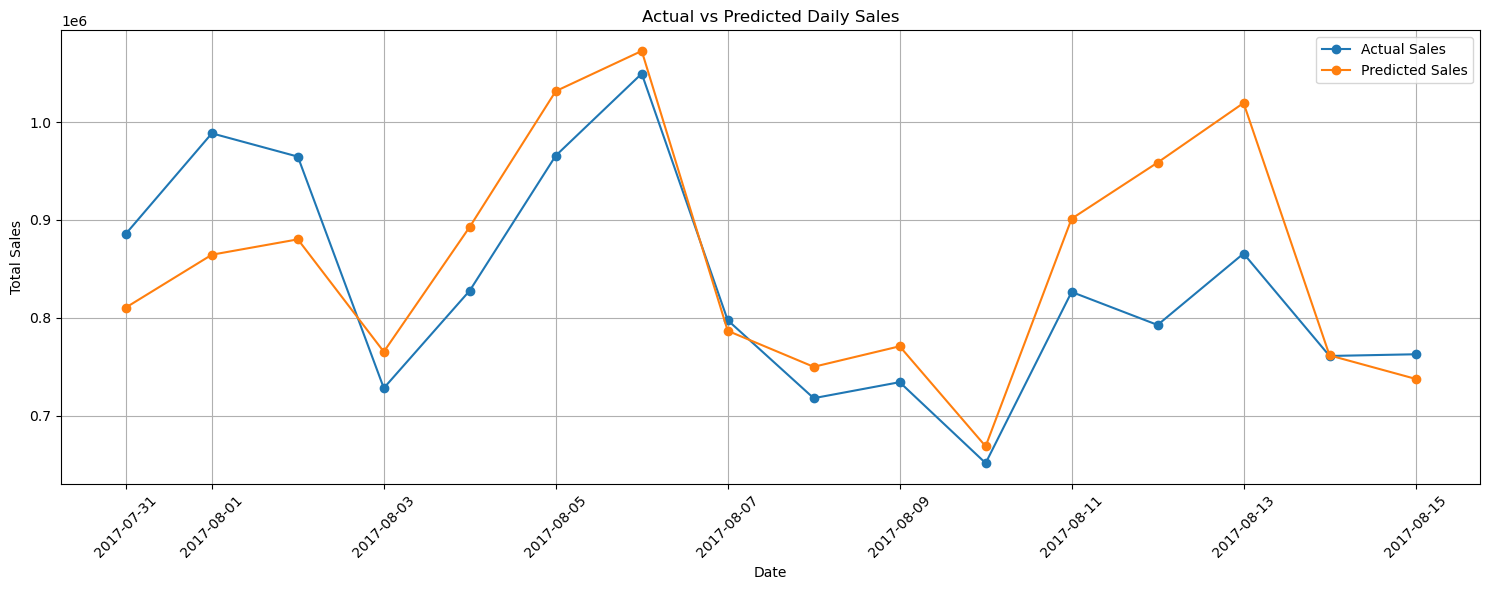

In [73]:
# Create Actual vs Predicted Sales 

# Prepare daily validation comparison
validation_comparison = pd.DataFrame({
    'date': train.loc[valid_mask, 'date'].to_numpy(),
    'actual_sales': actual_valid,
    'predicted_sales': predicted_valid
})

daily_comparison = validation_comparison.groupby(
    'date'
)[['actual_sales', 'predicted_sales']].sum()

# Plot actual vs predicted sales
plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison.index,
    daily_comparison['actual_sales'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    daily_comparison.index,
    daily_comparison['predicted_sales'],
    marker='o',
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


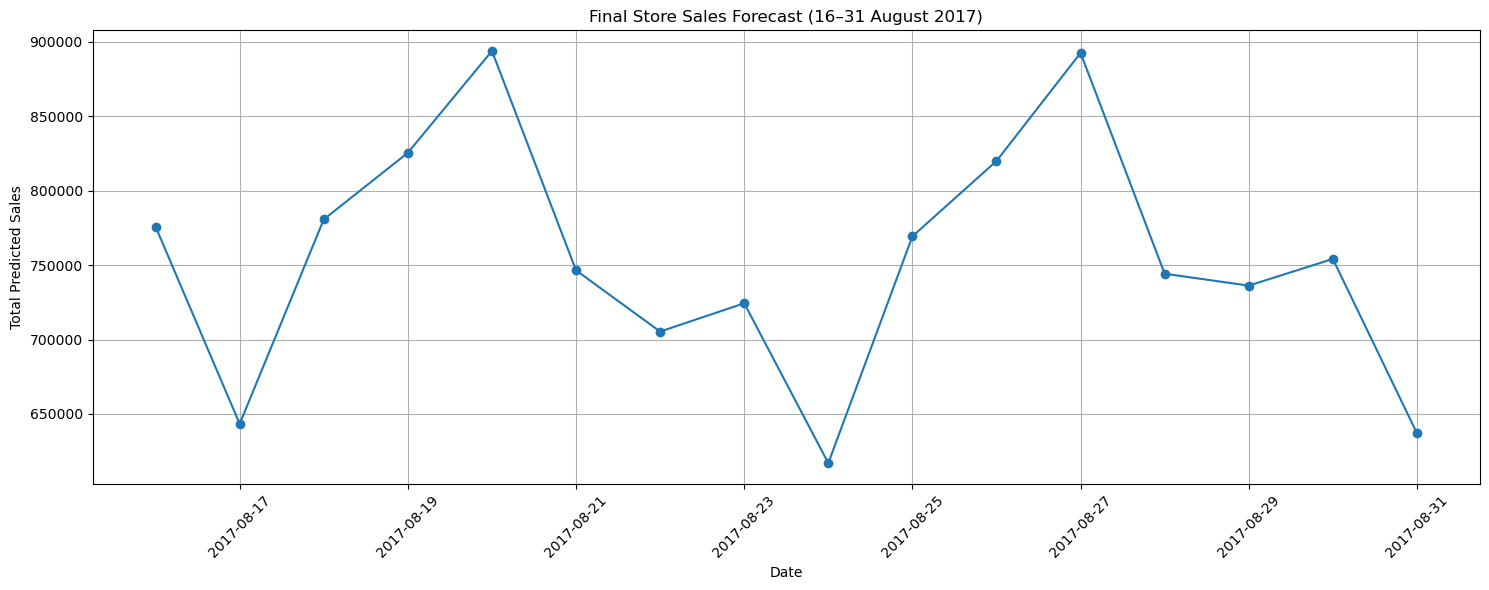

Total Forecasted Sales: 12065729.46
Average Daily Forecast: 754108.09


In [76]:
#  Visualize Final 16-Day Sales Forecast

# Prepare final forecast data
forecast_df = pd.DataFrame({
    'date': test['date'],
    'predicted_sales': test_predictions.to_numpy()
})

# Calculate total predicted sales per day
daily_forecast = forecast_df.groupby(
    'date'
)['predicted_sales'].sum()

# Plot final sales forecast
plt.figure(figsize=(15, 6))

plt.plot(
    daily_forecast.index,
    daily_forecast.values,
    marker='o'
)

plt.title('Final Store Sales Forecast (16–31 August 2017)')
plt.xlabel('Date')
plt.ylabel('Total Predicted Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

print("Total Forecasted Sales:",
      round(daily_forecast.sum(), 2))

print("Average Daily Forecast:",
      round(daily_forecast.mean(), 2))

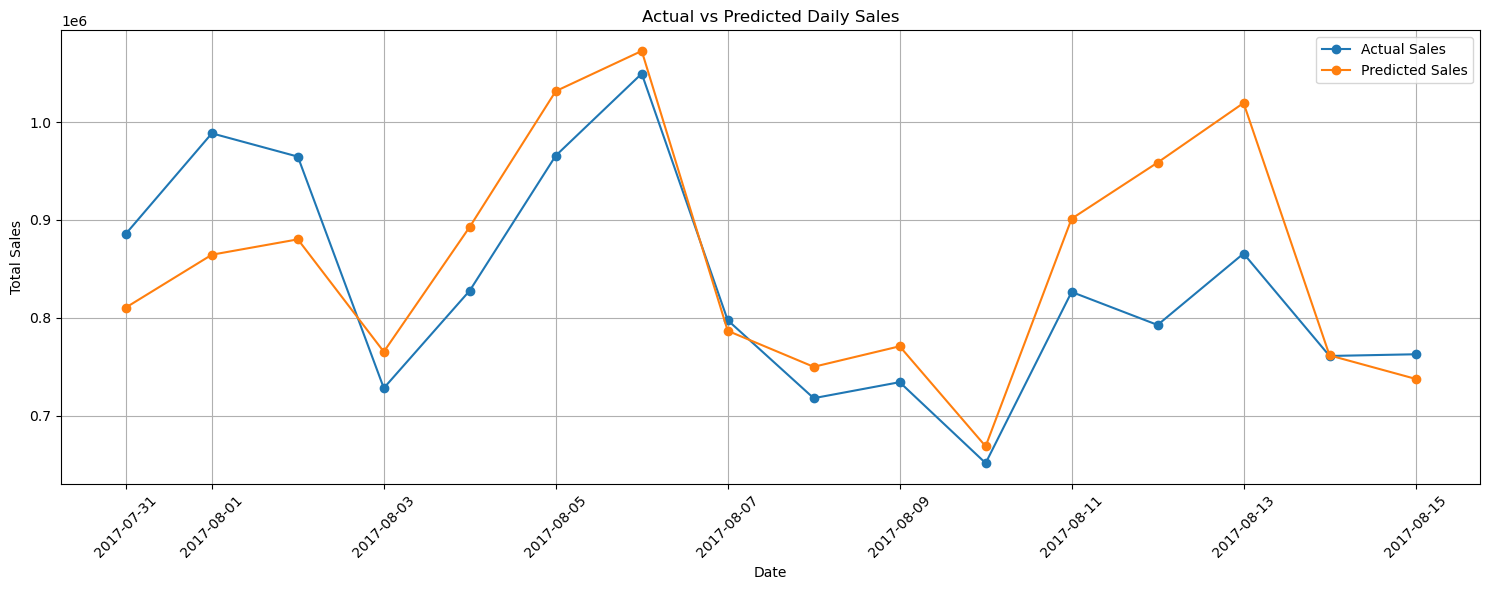

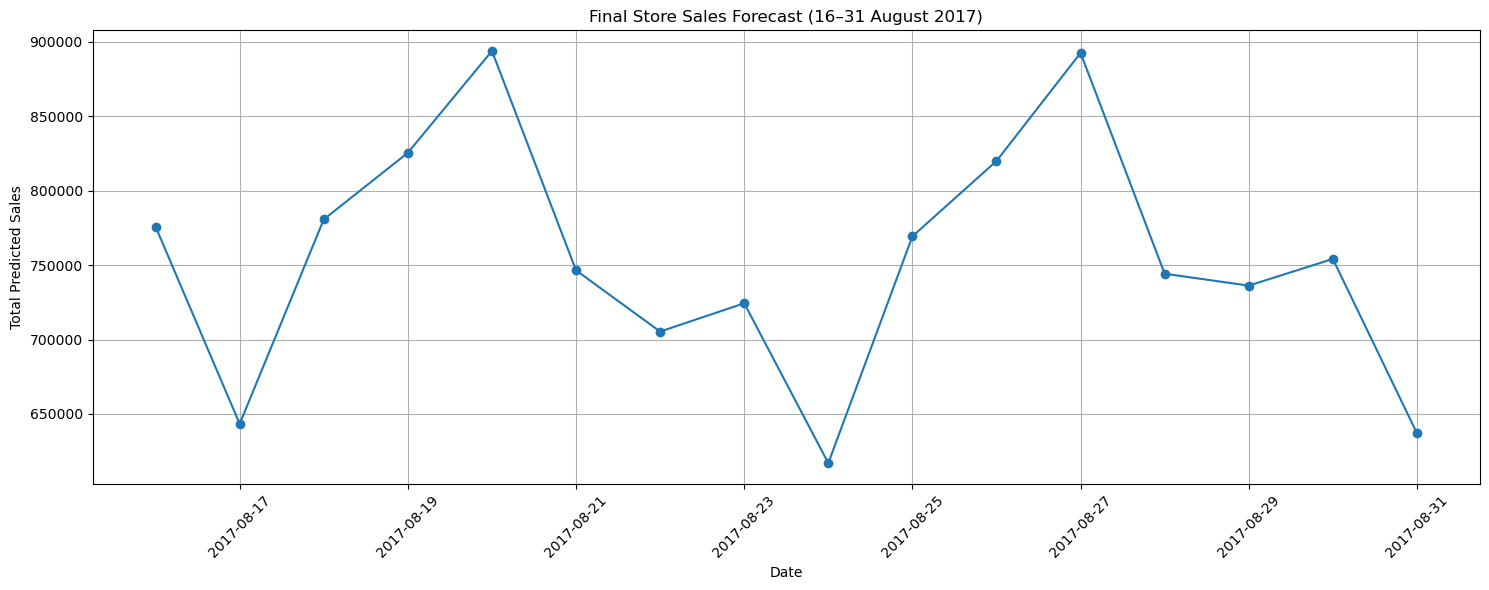

Both visualization files saved successfully!
Location: C:\Users\Simran\FutureInterns_ML


In [77]:
# Save Actual vs Predicted Sales Graph
plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison.index,
    daily_comparison['actual_sales'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    daily_comparison.index,
    daily_comparison['predicted_sales'],
    marker='o',
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    'Actual_vs_Predicted_Daily_Sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Save Final Sales Forecast Graph
plt.figure(figsize=(15, 6))

plt.plot(
    daily_forecast.index,
    daily_forecast.values,
    marker='o'
)

plt.title('Final Store Sales Forecast (16–31 August 2017)')
plt.xlabel('Date')
plt.ylabel('Total Predicted Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    'Final_16_Day_Sales_Forecast.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


print("Both visualization files saved successfully!")
print("Location:", os.getcwd())

## Final Project Summary

# Store Sales – Time Series Forecasting

## Project Objective
The objective of this project is to forecast daily sales for different stores and product families using historical sales patterns and machine learning regression techniques.

## Dataset Overview
- Training Records: 3,000,888
- Test Records: 28,512
- Stores: 54
- Product Families: 33
- Training Period: January 2013 – August 2017

## Data Processing and Feature Engineering
- Data cleaning and missing value handling
- Date-based feature engineering
- Store and product family information
- Oil price integration
- Holiday feature engineering
- Historical sales lag features (7, 14 and 28 days)
- Categorical feature encoding

## Machine Learning Model
HistGradientBoostingRegressor

## Model Evaluation

| Metric | Regression Model | Seasonal Naive |
|---|---:|---:|
| RMSLE | 0.4617 | 0.6170 |
| RMSE | 269.48 | 348.38 |
| MAE | 79.56 | 96.54 |

The regression model achieved a 25.18% lower RMSLE than the 7-day seasonal naive baseline.

## Final Forecast
- Forecast Period: 16–31 August 2017
- Total Predictions: 28,512
- Total Forecasted Sales: 12,065,729.46
- Average Daily Forecast: 754,108.09

## Project Outputs
- submission.csv
- Actual_vs_Predicted_Daily_Sales.png
- Final_16_Day_Sales_Forecast.png